In [6]:
#Import libraries
import pandas as pd
import numpy as np
import joblib
import shap
import matplotlib.pyplot as plt

import os
import glob

from google.colab import drive

In [7]:
#Load model and training data from Drive

# Mount Google Drive
drive.mount('/content/drive')

# Artifacts folder
folder = '/content/drive/MyDrive/Diabetes-Prediction/artifacts'

# Find only PKL models
model_files = glob.glob(os.path.join(folder, '*.joblib'))

print("Available Models:")

for i, file in enumerate(model_files):
    print(i + 1, os.path.basename(file))

# Select model
choice = int(input("\nEnter model number: ")) - 1

# Load selected model
model = joblib.load(model_files[choice])

print("\nModel Loaded Successfully!")
print("Selected Model:", os.path.basename(model_files[choice]))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Available Models:
1 preprocessor.joblib
2 diabetes_logistic_regression.joblib
3 SVM_Model.joblib

Enter model number: 3

Model Loaded Successfully!
Selected Model: SVM_Model.joblib


In [8]:
#Load training data
# Load processed training data
X_train = pd.read_csv(
    os.path.join(folder, 'X_train_processed.csv')
)

print("Training Data Loaded Successfully!")
print("Shape:", X_train.shape)

display(X_train.head())

Training Data Loaded Successfully!
Shape: (16000, 21)


,numerical__Age,numerical__Glucose,numerical__Blood Pressure,numerical__Skin Thickness,numerical__Insulin,numerical__BMI,numerical__Cholesterol,numerical__Diabetes Pedigree Function,binary__Family History,binary__Hypertension,...,categorical__Gender_Male,categorical__Physical Activity_High,categorical__Physical Activity_Low,categorical__Physical Activity_Moderate,categorical__Smoking Status_Current,categorical__Smoking Status_Former,categorical__Smoking Status_Never,categorical__Alcohol Intake_None,categorical__Alcohol Intake_Occasional,categorical__Alcohol Intake_Regular
0,0.430094,0.149000,-0.033516,-1.110615,-0.621085,-0.332109,0.353865,0.933214,0.0,0.0,...,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
1,-0.261740,1.198847,-0.116337,-1.438651,-0.998476,0.784292,-0.243316,-0.886887,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
2,1.237234,-0.731517,0.629047,-0.235851,-0.092738,1.184638,-0.072693,0.023885,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0
3,1.583151,1.097249,0.877508,-0.345197,-1.300389,1.325620,-1.693613,-1.612907,1.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
4,-1.011227,-0.731517,0.132124,-0.235851,-0.168216,0.265184,1.320730,-1.676416,0.0,0.0,...,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0


In [9]:
#Calculate SHAP values
# Select background and explanation samples
X_background = X_train.sample(
    min(50, len(X_train)), random_state=42
)

X_explain = X_train.sample(
    min(100, len(X_train)), random_state=42
)

# Prediction function
if hasattr(model, 'decision_function'):
    predict_fn = model.decision_function
else:
    predict_fn = lambda x: model.predict_proba(x)[:, 1]

# Create SHAP explainer
explainer = shap.KernelExplainer(
    predict_fn, X_background
)

# Calculate SHAP values
shap_values = explainer.shap_values(
    X_explain, nsamples=100
)

# Handle binary classification output
shap_values = np.asarray(shap_values)

if shap_values.ndim == 3:
    shap_values = shap_values[:, :, -1]

print("SHAP Values Calculated Successfully!")

  0%|          | 0/100 [00:00<?, ?it/s]

SHAP Values Calculated Successfully!


In [10]:
#Absolute SHAP feature importance
importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': np.abs(shap_values).mean(axis=0)
})

importance = importance.sort_values(
    by='Importance', ascending=False
)

display(importance)

,Feature,Importance
1,numerical__Glucose,2.108617
5,numerical__BMI,1.030267
6,numerical__Cholesterol,0.268621
4,numerical__Insulin,0.210338
2,numerical__Blood Pressure,0.210212
3,numerical__Skin Thickness,0.188210
7,numerical__Diabetes Pedigree Function,0.159308
0,numerical__Age,0.120179
20,categorical__Alcohol Intake_Regular,0.041546
13,categorical__Physical Activity_Low,0.035263


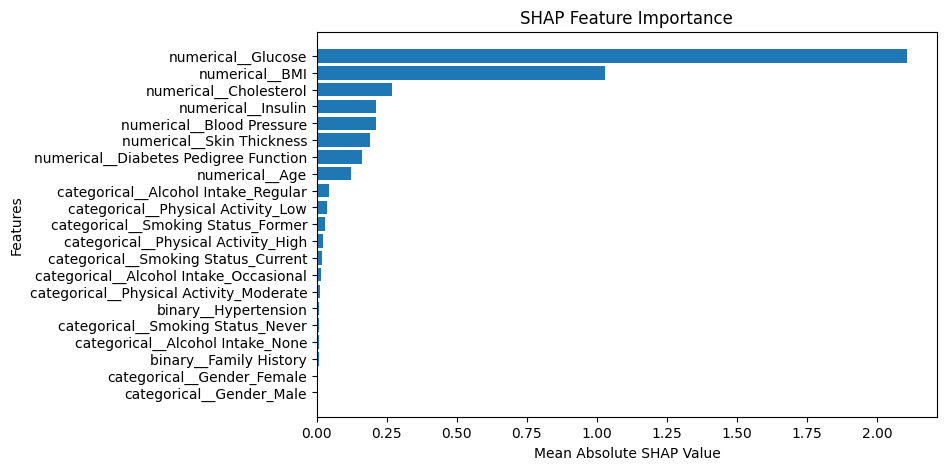

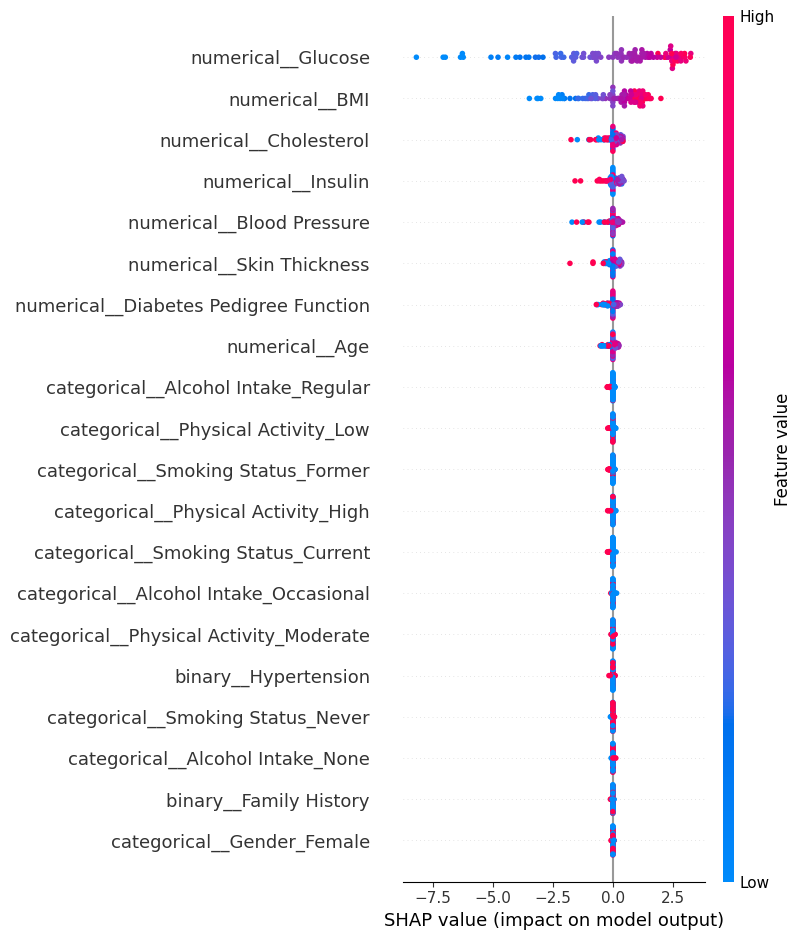

In [11]:
#SHAP importance graphs
plt.figure(figsize=(8, 5))

plt.barh(
    importance['Feature'],
    importance['Importance']
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Features")
plt.title("SHAP Feature Importance")

plt.gca().invert_yaxis()
plt.show()

#SHAP summary plot
shap.summary_plot(
    shap_values,
    X_explain,
    feature_names=X_train.columns
)

In [13]:
# Load processed datasets from Google Drive

X_train = pd.read_csv(os.path.join(folder, 'X_train_processed.csv'))
X_test = pd.read_csv(os.path.join(folder, 'X_test_processed.csv'))

y_train = pd.read_csv(os.path.join(folder, 'y_train.csv')).squeeze()
y_test = pd.read_csv(os.path.join(folder, 'y_test.csv')).squeeze()

print("All datasets loaded successfully!")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

All datasets loaded successfully!
X_train: (16000, 21)
X_test: (4000, 21)


In [17]:
import os
import pandas as pd

# Google Drive artifacts folder
folder = '/content/drive/MyDrive/Diabetes-Prediction/artifacts'

# Define top 5 features
features_5 = [
    'numerical__Glucose',
    'numerical__BMI',
    'numerical__Cholesterol',
    'numerical__Insulin',
    'numerical__Blood Pressure'
]

# Define top 8 features
features_8 = features_5 + [
    'numerical__Skin Thickness',
    'numerical__Diabetes Pedigree Function',
    'numerical__Age'
]

# Select 5 features
X_train_5 = X_train[features_5]
X_test_5 = X_test[features_5]

# Select 8 features
X_train_8 = X_train[features_8]
X_test_8 = X_test[features_8]

# Save 5-feature datasets
X_train_5.to_csv(os.path.join(folder, 'X_train_5features.csv'), index=False)
X_test_5.to_csv(os.path.join(folder, 'X_test_5features.csv'), index=False)

# Save 8-feature datasets
X_train_8.to_csv(os.path.join(folder, 'X_train_8features.csv'), index=False)
X_test_8.to_csv(os.path.join(folder, 'X_test_8features.csv'), index=False)

# Save target datasets
pd.Series(y_train).to_csv(os.path.join(folder, 'y_train.csv'), index=False)
pd.Series(y_test).to_csv(os.path.join(folder, 'y_test.csv'), index=False)

print("Feature-selected datasets saved successfully!")

print("5 Features:", X_train_5.shape, X_test_5.shape)
print("8 Features:", X_train_8.shape, X_test_8.shape)

Feature-selected datasets saved successfully!
5 Features: (16000, 5) (4000, 5)
8 Features: (16000, 8) (4000, 8)
